# Step 6: Bias analysis of the 1,500 processed job ads

Exploratory, rule-based analysis with an independent counter-validation. **No gold labels exist yet**, so every count below is a flag for human review, not a finding.

**Parts**
1. Data provenance: which datasets are used, from which step, and why.
2. Analysis on the primary dataset: explicit detection, implicit detection, job-ad labelling.
3. Counter-validation: the same questions re-answered on other datasets with a differently written implementation.

**Label rule (job-ad level, after Dikshit et al., 2024):** more masculine-coded words -> `agentic_masculine_coded`; more feminine-coded -> `communal_feminine_coded`; equal and non-zero -> `balanced`. We add `no_signal` for ads with no coded word.

## 1. Data provenance

In [1]:
import os, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import cohen_kappa_score

pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 110)
OUT = "outputs/equal_step6_bias_analysis"; os.makedirs(OUT, exist_ok=True)

SOURCES = {
    "D1": ("outputs/equal_step2_masking/step2_masked_analysis_text.csv", "masked_text"),
    "V1": ("outputs/equal_step1_structural_parsing/step1_modeling_fields.csv", "modeling_text"),
    "V2": ("outputs/equal_step3_text_normalization/step3_normalized_analysis_text.csv", "normalized_text"),
}
frames = {k: pd.read_csv(p).set_index("record_id") for k, (p, _) in SOURCES.items()}
ids = frames["D1"].index
for k, f in frames.items():
    assert set(f.index) == set(ids) and f.index.is_unique, f"{k}: record ids differ from D1"
TEXT = {k: frames[k][col].reindex(ids).fillna("") for k, (_, col) in SOURCES.items()}
EMP = frames["D1"]["employer_id"]
legacy = pd.read_csv("outputs/equal_data_preprocessing_bias/sentence_annotation_review.csv")

prov = pd.DataFrame([
    ("D1 (primary)", "Step 2: masking", SOURCES["D1"][0], SOURCES["D1"][1], len(TEXT["D1"]),
     "Designated modeling input. Employer, contact and source fields are masked; case and bullets are kept, so sentences and cased words stay intact."),
    ("V1 (validation)", "Step 1: structural parsing", SOURCES["V1"][0], SOURCES["V1"][1], len(TEXT["V1"]),
     "Same ads before masking. Tests whether masking removed, added or changed any gender-related wording."),
    ("V2 (validation)", "Step 3: normalization", SOURCES["V2"][0], SOURCES["V2"][1], len(TEXT["V2"]),
     "Lowercased, bullet-free, single-line text. Tests that results do not depend on case, line breaks or bullet markers."),
    ("V3 (validation)", "Original preprocessing notebook", "outputs/equal_data_preprocessing_bias/sentence_annotation_review.csv",
     "explicit_gender_hits, agentic_cue_hits, communal_cue_hits", legacy.record_id.nunique(),
     "Earlier, separately written cue extraction (15,914 sentence units). An independent lexicon and implementation to compare against."),
], columns=["dataset", "pipeline step", "file", "column(s) used", "ads", "why it is used"])
prov

,dataset,pipeline step,file,column(s) used,ads,why it is used
0,D1 (primary),Step 2: masking,outputs/equal_step2_masking/step2_masked_analysis_text.csv,masked_text,1500,"Designated modeling input. Employer, contact and source fields are masked; case and bullets are kept, so s..."
1,V1 (validation),Step 1: structural parsing,outputs/equal_step1_structural_parsing/step1_modeling_fields.csv,modeling_text,1500,"Same ads before masking. Tests whether masking removed, added or changed any gender-related wording."
2,V2 (validation),Step 3: normalization,outputs/equal_step3_text_normalization/step3_normalized_analysis_text.csv,normalized_text,1500,"Lowercased, bullet-free, single-line text. Tests that results do not depend on case, line breaks or bullet..."
3,V3 (validation),Original preprocessing notebook,outputs/equal_data_preprocessing_bias/sentence_annotation_review.csv,"explicit_gender_hits, agentic_cue_hits, communal_cue_hits",1500,"Earlier, separately written cue extraction (15,914 sentence units). An independent lexicon and implementat..."


## 2. Analysis on the primary dataset (D1, Step 2 masked text)

**Rules**
- *Explicit:* a sentence naming only men or only women is `restrictive`; one naming both ("Male/Female") or stating no gender preference is `inclusive`. Gendered occupational titles (e.g. foreman, waitress) and he/she pronouns are counted separately.
- *Implicit:* Gaucher et al. (2011) word stems (Gender Decoder implementation) plus gender-linked proxies (marital status, age limits, appearance/physical wording).
- *Enhancements over the first script:* sentence-level output, a documented false-positive exclusion list, mixed-restriction handling, an inclusive-only category, a core-word sensitivity run (duty-prone stems removed), and employer-level concentration checks.

In [2]:
MASC = ("active adventurous aggress ambitio analy assert athlet autonom boast challeng compet confident "
        "courag decisive decision determin dominan driven fearless force headstrong hierarch impulsive "
        "independen individual intellect lead logic objective opinion outspoken persist self-relian "
        "self-sufficien stubborn superior unreasonab").split()
FEM = ("agree affectionate child cheer collab commit communal compassion connect considerate cooperat "
       "depend emotiona empath feel flatterable gentle honest interpersonal interdependen kind kinship "
       "loyal modest nurtur pleasant polite quiet respons sensitiv submissive support sympath tender "
       "together trust understand warm enthusias inclusive yield share").split()

# Words that share a stem with a coded word but do not carry the trait
FALSE_POSITIVE_PREFIXES = ("confidential", "committee", "shareholder", "kinds")
# Stems that in job ads usually describe duties, not personality; used only for the sensitivity run
DUTY_PRONE = {"analy", "lead", "respons", "support", "decision", "commit", "connect", "understand", "share", "depend"}
MASC_CORE = [s for s in MASC if s not in DUTY_PRONE]
FEM_CORE = [s for s in FEM if s not in DUTY_PRONE]

def coded_words(text, stems):
    words = re.findall(r"[a-z][a-z-]*", text.lower())
    hits = []
    for w in words:
        if w.startswith(FALSE_POSITIVE_PREFIXES): continue
        # hyphenated compounds are also checked part by part ("performance-driven" -> "driven")
        parts = [w] + (w.split("-") if "-" in w else [])
        if any(p.startswith(s) for p in parts for s in stems): hits.append(w)
    return hits

# Restrictive wording uses plural/adjective forms. Singular nouns (man, boy, woman, girl, lady) are
# gender-marked occupational nouns ("Farm Boy", "Steel man"): retained and reported separately.
MALE_RE = re.compile(r"\b(?:male|males|men|gentlemen)\b", re.I)
FEMALE_RE = re.compile(r"\b(?:female|females|women|ladies)\b", re.I)
NOUN_RE = re.compile(r"\b(?:man|boys?|gentleman|woman|girls?|lady)\b", re.I)
NETWORK_RE = re.compile(r"\bWAN\b")  # "LAN, WAN, MAN" is a network type, not a gendered noun
INCLUSIVE_RE = re.compile(r"\b(?:either\s+gender|any\s+gender|regardless\s+of\s+(?:sex|gender)|men\s+and\s+women|"
                          r"gender\s*[:\-]?\s*(?:any|open|not\s+required))\b", re.I)
TITLE_MALE = re.compile(r"\b(?:salesman|salesmen|houseboy|busboy|delivery\s+boy|utility\s+man|foreman|watchman|handyman|"
                        r"repairman|serviceman|chairman|businessman|cameraman|gentleman)\b", re.I)
TITLE_FEMALE = re.compile(r"\b(?:saleslady|salesgirl|sales\s+lady|waitress|stewardess|madam|maid|manicurist)\b", re.I)
PRONOUN_RE = re.compile(r"\b(?:he|she|his|him|hers)\b", re.I)
PROXIES = {
    "marital_status": re.compile(r"\b(?:single|married|unmarried|widow(?:ed|er)?|marital|pregnan\w*)\b", re.I),
    "age_limit": re.compile(r"\b(?:\d{2}\s*(?:-|to)\s*\d{2}\s*(?:years|yrs|yo|y/o|years\s+old)|"
                            r"(?:below|under|not\s+(?:more|older)\s+than|up\s+to|maximum\s+(?:age\s+)?of)\s*\d{2}|"
                            r"age[sd]?\s*(?:range|limit|requirement)?\s*[:\-]?\s*\d{2})\b", re.I),
    "appearance_physical": re.compile(r"\b(?:good\s+looking|pleasing\s+personality|presentable|attractive|"
                                      r"height|weight|physically\s+fit|heavy\s+lifting|tall|slim)\b", re.I),
}

SPLIT = re.compile(r"(?<=[.!?])\s+")
def units(text):
    out = []
    for line in text.split("\n"):
        line = re.sub(r"^\s*[•\-\*]\s*", "", line).strip()
        out += [p.strip() for p in SPLIT.split(line) if re.search(r"[A-Za-z]", p)]
    return out

def unit_type_regex(s):
    hm, hf = bool(MALE_RE.search(s)), bool(FEMALE_RE.search(s))
    if INCLUSIVE_RE.search(s) or (hm and hf): return "inclusive"
    return "restrictive_male" if hm else ("restrictive_female" if hf else None)

def ad_direction(types):
    t = set(types)
    hm, hf = "restrictive_male" in t, "restrictive_female" in t
    if hm and hf: return "mixed_restrictions"
    if hm: return "male_restricted"
    if hf: return "female_restricted"
    if "inclusive" in t: return "inclusive_only"
    return "none"

def coded_label(m, f):
    if m + f == 0: return "no_signal"
    return "agentic_masculine_coded" if m > f else ("communal_feminine_coded" if m < f else "balanced")

def analyse(rid, text):
    us = units(text)
    types, ev, srows, nouns, diff = [], [], [], 0, 0
    for i, s in enumerate(us):
        t = unit_type_regex(s)
        mh, fh = coded_words(s, MASC), coded_words(s, FEM)
        srows.append((rid, i, s, t or "", len(mh), len(fh)))
        if t: types.append(t); ev.append((rid, "explicit_" + t, s))
        if t is None and NOUN_RE.search(s) and not NETWORK_RE.search(s):
            nouns += 1; ev.append((rid, "gendered_noun", s))
        # one sentence giving different standards for men and women (e.g. height)
        if t == "inclusive" and MALE_RE.search(s) and FEMALE_RE.search(s) and re.search(r"\d", s):
            diff += 1; ev.append((rid, "gender_differentiated_requirement", s))
    tm, tf = TITLE_MALE.findall(text), TITLE_FEMALE.findall(text)
    for x in tm + tf: ev.append((rid, "gendered_title", x.lower()))
    mh, fh = coded_words(text, MASC), coded_words(text, FEM)
    mc, fc = coded_words(text, MASC_CORE), coded_words(text, FEM_CORE)
    row = dict(record_id=rid, n_words=len(text.split()), n_units=len(us),
               masc_hits=len(mh), fem_hits=len(fh), masc_words="|".join(sorted(set(mh))), fem_words="|".join(sorted(set(fh))),
               core_masc_hits=len(mc), core_fem_hits=len(fc),
               explicit_direction=ad_direction(types), title_male=len(tm), title_female=len(tf),
               pronouns=len(PRONOUN_RE.findall(text)), gendered_noun_units=nouns, gender_differentiated=diff,
               **{"proxy_" + k: len(p.findall(text)) for k, p in PROXIES.items()})
    return row, srows, ev

res = [analyse(r, TEXT["D1"][r]) for r in ids]
d = pd.DataFrame([x[0] for x in res]).set_index("record_id")
sent = pd.DataFrame([r for x in res for r in x[1]], columns=["record_id", "unit_index", "sentence", "explicit_unit_type", "masc_hits", "fem_hits"])
evidence = pd.DataFrame([r for x in res for r in x[2]], columns=["record_id", "evidence_type", "evidence_text"])
d["employer_id"] = EMP

d["coded_label"] = [coded_label(m, f) for m, f in zip(d.masc_hits, d.fem_hits)]
d["coded_label_core"] = [coded_label(m, f) for m, f in zip(d.core_masc_hits, d.core_fem_hits)]
d["proxy_any"] = d[[c for c in d if c.startswith("proxy_")]].sum(axis=1) > 0
d["title_or_pronoun"] = (d.title_male + d.title_female + d.pronouns + d.gendered_noun_units) > 0
d["bias_category"] = np.select(
    [d.explicit_direction.isin(["male_restricted", "female_restricted", "mixed_restrictions"]),
     d.title_or_pronoun,
     (d.masc_hits + d.fem_hits > 0) | d.proxy_any,
     d.explicit_direction == "inclusive_only"],
    ["explicit_restrictive", "explicit_title_or_pronoun", "implicit_only", "inclusive_statement_only"],
    default="none_detected")
print("ads analysed:", len(d), "| sentence units:", len(sent), "| evidence rows:", len(evidence))

ads analysed: 1500 | sentence units: 8005 | evidence rows: 465


### 2.1 Job-ad labels (coded-word balance)

In [3]:
lab = d.coded_label.value_counts().rename("ads").to_frame(); lab["share_%"] = (lab.ads / len(d) * 100).round(1)
display(lab)
print("Median words per ad:", d.n_words.median(), "| ads with any coded word:", int((d.masc_hits + d.fem_hits > 0).sum()))
core = pd.crosstab(d.coded_label, d.coded_label_core)
print("\nSensitivity: full Gaucher list (rows) vs core list without duty-prone stems (columns)")
display(core)

,ads,share_%
coded_label,,
no_signal,1090,72.7
communal_feminine_coded,193,12.9
agentic_masculine_coded,164,10.9
balanced,53,3.5


Median words per ad: 32.0 | ads with any coded word: 410

Sensitivity: full Gaucher list (rows) vs core list without duty-prone stems (columns)


coded_label_core,agentic_masculine_coded,balanced,communal_feminine_coded,no_signal
coded_label,,,,
agentic_masculine_coded,48,5,9,102
balanced,5,8,27,13
communal_feminine_coded,2,1,133,57
no_signal,0,0,0,1090


### 2.2 Explicit and implicit detection

In [4]:
print("Bias category (mutually exclusive, in priority order):")
display(d.bias_category.value_counts().rename("ads").to_frame())
print("Explicit direction (ad level):")
display(d.explicit_direction.value_counts().rename("ads").to_frame())
prox = pd.Series({c: int((d[c] > 0).sum()) for c in d if c.startswith("proxy_")}, name="ads").to_frame()
prox.loc["title_male"] = int((d.title_male > 0).sum()); prox.loc["title_female"] = int((d.title_female > 0).sum())
prox.loc["pronouns"] = int((d.pronouns > 0).sum())
prox.loc["gendered_noun (man/boy/woman/girl/lady alone)"] = int((d.gendered_noun_units > 0).sum())
prox.loc["gender_differentiated_requirement"] = int((d.gender_differentiated > 0).sum())
display(prox)

def top_words(col, n=12):
    return pd.Series("|".join(d[col]).split("|")).replace("", np.nan).dropna().value_counts().head(n)
print("Most frequent masculine-coded words:", top_words("masc_words").to_dict())
print("Most frequent feminine-coded words :", top_words("fem_words").to_dict())
print("\nCoded label x explicit direction (does the dictionary label track explicit restriction?)")
display(pd.crosstab(d.coded_label, d.explicit_direction))

Bias category (mutually exclusive, in priority order):


,ads
bias_category,
none_detected,717
implicit_only,380
explicit_restrictive,320
inclusive_statement_only,53
explicit_title_or_pronoun,30


Explicit direction (ad level):


,ads
explicit_direction,
none,1078
male_restricted,207
female_restricted,112
inclusive_only,102
mixed_restrictions,1


,ads
proxy_marital_status,48
proxy_age_limit,21
proxy_appearance_physical,92
proxy_any,148
title_male,28
title_female,1
pronouns,3
gendered_noun (man/boy/woman/girl/lady alone),3
gender_differentiated_requirement,2


Most frequent masculine-coded words: {'analytical': 70, 'leadership': 46, 'analyst': 23, 'analysis': 22, 'analyze': 14, 'leader': 13, 'active': 12, 'decision': 12, 'independently': 11, 'driven': 10, 'leading': 9, 'assertive': 8}
Most frequent feminine-coded words : {'interpersonal': 100, 'honest': 52, 'trustworthy': 38, 'support': 34, 'responsible': 25, 'understand': 16, 'understanding': 13, 'commitment': 8, 'sensitive': 7, 'responsibility': 7, 'dependable': 6, 'understands': 6}

Coded label x explicit direction (does the dictionary label track explicit restriction?)


explicit_direction,female_restricted,inclusive_only,male_restricted,mixed_restrictions,none
coded_label,,,,,
agentic_masculine_coded,6,10,14,0,134
balanced,6,5,4,0,38
communal_feminine_coded,14,13,23,0,143
no_signal,86,74,166,1,763


### 2.3 Concentration and duplication checks
Repeated templates can inflate counts. We report how many employers and how many distinct ad texts sit behind each explicit category.

In [5]:
d["_text"] = TEXT["D1"].reindex(d.index)
rows = []
for cat, g in d.groupby("bias_category"):
    top_emp = g.employer_id.value_counts()
    rows.append(dict(category=cat, ads=len(g), employers=g.employer_id.nunique(),
                     distinct_texts=g._text.nunique(), top_employer_share_pct=round(top_emp.iloc[0] / len(g) * 100, 1)))
conc = pd.DataFrame(rows).set_index("category"); display(conc)
dr = d[d.explicit_direction.isin(["male_restricted", "female_restricted"])]
print("Male- vs female-restricted ads:", dr.explicit_direction.value_counts().to_dict(),
      "| employers:", dr.groupby("explicit_direction").employer_id.nunique().to_dict(),
      "| distinct texts:", dr.groupby("explicit_direction")._text.nunique().to_dict())
d = d.drop(columns="_text")

,ads,employers,distinct_texts,top_employer_share_pct
category,,,,
explicit_restrictive,320,126,306,5.0
explicit_title_or_pronoun,30,16,29,30.0
implicit_only,380,143,365,5.0
inclusive_statement_only,53,25,49,15.1
none_detected,717,189,681,4.6


Male- vs female-restricted ads: {'male_restricted': 207, 'female_restricted': 112} | employers: {'female_restricted': 66, 'male_restricted': 87} | distinct texts: {'female_restricted': 104, 'male_restricted': 201}


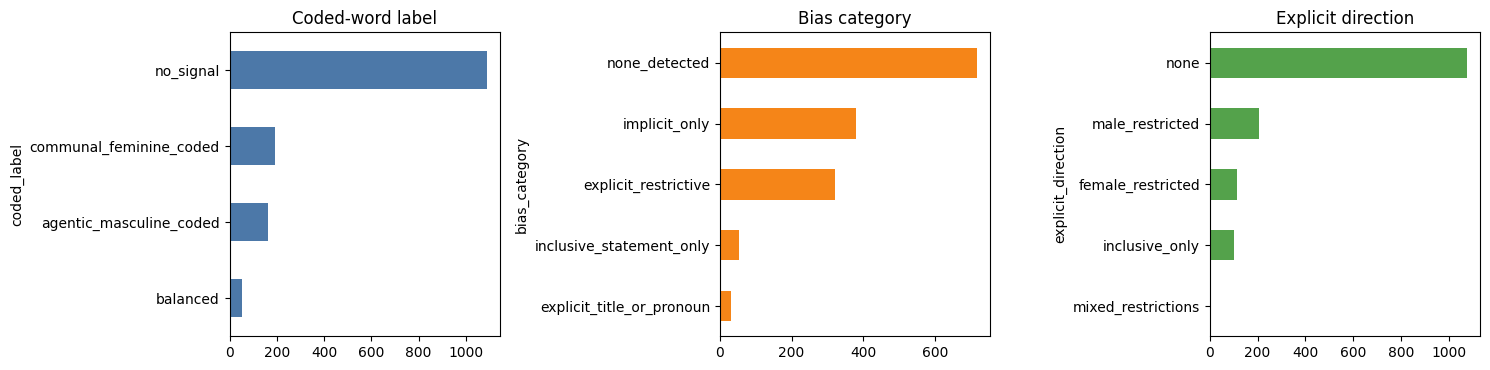

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
d.coded_label.value_counts().plot.barh(ax=ax[0], color="#4C78A8"); ax[0].set_title("Coded-word label")
d.bias_category.value_counts().plot.barh(ax=ax[1], color="#F58518"); ax[1].set_title("Bias category")
d.explicit_direction.value_counts().plot.barh(ax=ax[2], color="#54A24B"); ax[2].set_title("Explicit direction")
for a in ax: a.invert_yaxis()
plt.tight_layout(); plt.savefig(f"{OUT}/step6_overview.png", dpi=130); plt.show()

### 2.4 Save outputs and human-review sample

In [7]:
d.reset_index().to_csv(f"{OUT}/step6_ad_level_analysis.csv", index=False)
sent.to_csv(f"{OUT}/step6_sentence_level.csv", index=False)
evidence.to_csv(f"{OUT}/step6_evidence.csv", index=False)

parts = [g.sample(min(len(g), 40), random_state=42) for _, g in d.groupby("bias_category")]
rv = pd.concat(parts).reset_index()
rv["text"] = rv.record_id.map(TEXT["D1"])
rv = rv[["record_id", "bias_category", "explicit_direction", "coded_label", "masc_words", "fem_words", "text"]]
for c in ["human_explicit", "human_implicit", "human_label", "notes"]: rv[c] = ""
rv.to_csv(f"{OUT}/step6_human_review_sample.csv", index=False)
print("saved:", sorted(os.listdir(OUT)))

saved: ['step6_ad_level_analysis.csv', 'step6_evidence.csv', 'step6_human_review_sample.csv', 'step6_overview.png', 'step6_sentence_level.csv', 'step6_validation_disagreements.csv', 'step6_validation_headline_counts.csv', 'step6_validation_summary.csv']


## 3. Counter-validation

The analysis is re-run on **other datasets** and with a **differently written implementation**, then compared with Section 2.

| Check | Dataset | What differs | Question |
|---|---|---|---|
| A | V1, Step 1 (unmasked) | Different text version and an independent code path (token sets, one compiled regex) | Does masking change gender-related wording, and is the logic reproducible? |
| B | V2, Step 3 (normalized) | Lowercase, no bullets, one line | Are results independent of case and formatting? |
| C | V3, original notebook cues | Different lexicon and extraction code | Do two separately built extractors agree? |

Agreement is reported as raw agreement and Cohen's kappa. A disagreement is not an error in either side until it is read; the disagreement lists are saved.

In [8]:
# Independent implementation: token sets and one compiled stem regex (no shared code with Section 2 except the lexicons)
MALE_TOK = {"male", "males", "men", "gentlemen"}
FEMALE_TOK = {"female", "females", "women", "ladies"}
INCL_PHRASES = ("either gender", "any gender", "regardless of sex", "regardless of gender", "men and women")
STEM_M = re.compile(r"\b(?:" + "|".join(re.escape(s) for s in MASC) + r")[a-z-]*")
STEM_F = re.compile(r"\b(?:" + "|".join(re.escape(s) for s in FEM) + r")[a-z-]*")

def indep(text):
    low = text.lower()
    types = []
    for seg in re.split(r"[\n!?;]+|(?<!\d)\.(?!\d)", low):
        toks = set(re.findall(r"[a-z]+", seg))
        hm, hf = bool(toks & MALE_TOK), bool(toks & FEMALE_TOK)
        if hm and hf or any(p in seg for p in INCL_PHRASES): types.append("inclusive")
        elif hm: types.append("restrictive_male")
        elif hf: types.append("restrictive_female")
    m = [w for w in STEM_M.findall(low) if not w.startswith(FALSE_POSITIVE_PREFIXES)]
    f = [w for w in STEM_F.findall(low) if not w.startswith(FALSE_POSITIVE_PREFIXES)]
    return dict(direction=ad_direction(types), masc=len(m), fem=len(f), label=coded_label(len(m), len(f)))

def compare(name, text):
    r = pd.DataFrame({rid: indep(text[rid]) for rid in ids}).T
    r["masc"], r["fem"] = r["masc"].astype(int), r["fem"].astype(int)
    out = dict(check=name,
               direction_agree_pct=round((r.direction == d.explicit_direction).mean() * 100, 2),
               direction_kappa=round(cohen_kappa_score(d.explicit_direction, r.direction), 3),
               label_agree_pct=round((r.label == d.coded_label).mean() * 100, 2),
               label_kappa=round(cohen_kappa_score(d.coded_label, r.label), 3),
               masc_count_equal_pct=round((r.masc == d.masc_hits).mean() * 100, 2),
               fem_count_equal_pct=round((r.fem == d.fem_hits).mean() * 100, 2))
    return out, r

chkA, rA = compare("A: V1 Step 1 unmasked, independent code", TEXT["V1"])
chkB, rB = compare("B: V2 Step 3 normalized, independent code", TEXT["V2"])
display(pd.DataFrame([chkA, chkB]).set_index("check"))

,direction_agree_pct,direction_kappa,label_agree_pct,label_kappa,masc_count_equal_pct,fem_count_equal_pct
check,,,,,,
"A: V1 Step 1 unmasked, independent code",100.00,1.000,100.0,1.0,100.0,100.0
"B: V2 Step 3 normalized, independent code",99.93,0.999,100.0,1.0,100.0,100.0


### 3.1 Disagreements for A and B (read these before accepting the numbers)

In [9]:
def disagreements(r, source):
    m = (r.direction != d.explicit_direction) | (r.label != d.coded_label)
    x = pd.DataFrame({"D1_direction": d.explicit_direction, "other_direction": r.direction,
                      "D1_label": d.coded_label, "other_label": r.label,
                      "D1_masc/fem": d.masc_hits.astype(str) + "/" + d.fem_hits.astype(str),
                      "other_masc/fem": r.masc.astype(str) + "/" + r.fem.astype(str)})[m]
    x.insert(0, "source", source); return x
dis = pd.concat([disagreements(rA, "V1"), disagreements(rB, "V2")])
print("ads with at least one disagreement:", dis.index.nunique())
display(dis.head(15))
dis.reset_index().to_csv(f"{OUT}/step6_validation_disagreements.csv", index=False)

ads with at least one disagreement: 1


,source,D1_direction,other_direction,D1_label,other_label,D1_masc/fem,other_masc/fem
row-1427,V2,mixed_restrictions,inclusive_only,no_signal,no_signal,0/0,0/0


In [10]:
# Which text differences explain the disagreements?
for src in ["V1", "V2"]:
    for rid in list(dis[dis.source == src].index.unique())[:5]:
        print(src, rid, "| D1:", repr(TEXT["D1"][rid][:140]))
        print("        ", src, ":", repr(TEXT[src][rid][:140]))

V2 row-1427 | D1: 'Sales Officer\n• Female\n• Male preferably can drive\n• At least 1 to 2 years of work experience in sales\n• College Level\n• Willing to work in '
         V2 : 'sales officer female male preferably can drive at least 1 to 2 years of work experience in sales college level willing to work in laguna are'


**How to read the disagreements.** A disagreement on `V2` that involves separate one-line requirements (e.g. "Female" and "Male preferably ...") is caused by Step 3 joining lines: two requirements merge into one sentence. This is why the Step 3 text is used for robustness checks only and never for segmentation. Disagreements on `V1` indicate a masking effect or a rule difference.

### 3.2 Check C: original-notebook cue extraction (V3)

In [11]:
def legacy_ad_table(leg):
    g = leg.groupby("record_id")
    def terms(s):
        return [t.strip().lower() for v in s.dropna() for t in str(v).split("|") if t.strip()]
    out = pd.DataFrame({
        "agentic": g.agentic_cue_hits.apply(lambda s: len(terms(s))),
        "communal": g.communal_cue_hits.apply(lambda s: len(terms(s))),
        "gender": g.explicit_gender_hits.apply(lambda s: sorted({t for t in terms(s)})),
    }).reindex(ids)
    out[["agentic", "communal"]] = out[["agentic", "communal"]].fillna(0).astype(int)
    out["gender"] = out.gender.apply(lambda v: v if isinstance(v, list) else [])
    out["leg_direction3"] = out.gender.apply(lambda v: "none" if not v else ("both" if len(v) > 1 else v[0]))
    out["leg_label"] = [coded_label(a, c) for a, c in zip(out.agentic, out.communal)]
    return out

L = legacy_ad_table(legacy)
d3 = d.explicit_direction.map({"male_restricted": "male", "female_restricted": "female", "mixed_restrictions": "both",
                               "inclusive_only": "both", "none": "none"})
print("Explicit direction, D1 (rows) vs original notebook (columns):")
display(pd.crosstab(d3, L.leg_direction3))
print("Coded label, D1 (rows) vs original notebook cue lists (columns):")
display(pd.crosstab(d.coded_label, L.leg_label))
chkC = dict(check="C: V3 original notebook cues",
            direction_agree_pct=round((d3 == L.leg_direction3).mean() * 100, 2),
            direction_kappa=round(cohen_kappa_score(d3, L.leg_direction3), 3),
            label_agree_pct=round((d.coded_label == L.leg_label).mean() * 100, 2),
            label_kappa=round(cohen_kappa_score(d.coded_label, L.leg_label), 3))
display(pd.DataFrame([chkC]).set_index("check"))

Explicit direction, D1 (rows) vs original notebook (columns):


leg_direction3,both,female,male,man,none
explicit_direction,,,,,
both,103,0,0,0,0
female,0,112,0,0,0
male,2,0,205,0,0
none,0,0,0,2,1076


Coded label, D1 (rows) vs original notebook cue lists (columns):


leg_label,agentic_masculine_coded,balanced,communal_feminine_coded,no_signal
coded_label,,,,
agentic_masculine_coded,35,15,18,96
balanced,6,9,20,18
communal_feminine_coded,4,0,66,123
no_signal,1,0,48,1041


,direction_agree_pct,direction_kappa,label_agree_pct,label_kappa
check,,,,
C: V3 original notebook cues,99.73,0.994,76.73,0.361


### 3.3 Reproduced headline counts across datasets

In [12]:
def headline(label, dirn):
    return pd.concat([label.value_counts().rename(lambda x: "label: " + x),
                      dirn.value_counts().rename(lambda x: "direction: " + x)])
tab = pd.concat({
    "D1 Step 2 (primary)": headline(d.coded_label, d.explicit_direction),
    "V1 Step 1 (indep. code)": headline(rA.label, rA.direction),
    "V2 Step 3 (indep. code)": headline(rB.label, rB.direction),
}, axis=1).fillna(0).astype(int)
display(tab)
tab.to_csv(f"{OUT}/step6_validation_headline_counts.csv")

,D1 Step 2 (primary),V1 Step 1 (indep. code),V2 Step 3 (indep. code)
label: no_signal,1090,1090,1090
label: communal_feminine_coded,193,193,193
label: agentic_masculine_coded,164,164,164
label: balanced,53,53,53
direction: none,1078,1078,1078
direction: male_restricted,207,207,207
direction: female_restricted,112,112,112
direction: inclusive_only,102,102,103
direction: mixed_restrictions,1,1,0


### 3.4 Validation summary

In [13]:
summ = pd.DataFrame([chkA, chkB, chkC]).set_index("check")
summ.to_csv(f"{OUT}/step6_validation_summary.csv")
display(summ)
print("Interpretation rules: kappa >= 0.80 is treated as strong agreement. Anything lower is reported with its cause, not hidden.")

,direction_agree_pct,direction_kappa,label_agree_pct,label_kappa,masc_count_equal_pct,fem_count_equal_pct
check,,,,,,
"A: V1 Step 1 unmasked, independent code",100.00,1.000,100.00,1.000,100.0,100.0
"B: V2 Step 3 normalized, independent code",99.93,0.999,100.00,1.000,100.0,100.0
C: V3 original notebook cues,99.73,0.994,76.73,0.361,NaN,NaN


Interpretation rules: kappa >= 0.80 is treated as strong agreement. Anything lower is reported with its cause, not hidden.


## 4. Reading guide and limits
- Agreement between implementations shows the **rules are applied consistently**. It does not show they are **correct**. Only the human-review sample can measure precision and recall.
- Both `V1` and `V2` come from the same 1,500 ads, so they check robustness to text processing, not generalisation to other corpora.
- `V3` uses a different cue list; low agreement there reflects lexicon differences as much as errors.
- The Gaucher stems are the Gender Decoder implementation, designed for US English; they are not validated for Philippine ads.
- Duty-prone stems (analy*, lead*, respons*, support*, ...) may describe the job, not personality; compare `coded_label` with `coded_label_core`.
- Next: judge `step6_human_review_sample.csv`, then compute precision per rule.